# Atelier 1 — Régression (Machine Learning, LSI S3, 2024/2025)
**Université Abdelmalek Essaadi — FST Tanger — Département Génie Informatique**

Objectif : pratiquer la régression linéaire simple, multiple et polynomiale sur trois jeux de données
(Expérience/Salaire, Assurance, China GDP) avec Python, Pandas, Scikit-learn et Matplotlib.

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import scatter_matrix

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
os.makedirs("figures", exist_ok=True)
SEED = 42
RESULTS = {}          # métriques sauvegardées dans results.json (utilisées par le rapport)


def save(fig, name):
    fig.tight_layout(rect=(0, 0, 1, 0.97) if fig._suptitle else None)
    fig.savefig(f"figures/{name}.png", dpi=150)
    plt.show()


def evaluate(y_true, y_pred):
    """MSE, RMSE, MAE (+ R² en complément)."""
    mse = mean_squared_error(y_true, y_pred)
    return {"MSE": float(mse), "RMSE": float(np.sqrt(mse)),
            "MAE": float(mean_absolute_error(y_true, y_pred)), "R2": float(r2_score(y_true, y_pred))}

---
# Partie 1 — Data Visualisation
## 1. Exploration des données avec pandas

In [2]:
salary = pd.read_csv("data/salary.csv")
insurance = pd.read_csv("data/insurance.csv")
gdp = pd.read_csv("data/china_gdp.csv")

print("=== Expérience / Salaire ===", salary.shape)
display(salary.head())
salary.info()
print("\nValeurs manquantes :\n", salary.isna().sum().to_string())
print("Doublons :", salary.duplicated().sum())

=== Expérience / Salaire === (30, 2)


,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes

Valeurs manquantes :
 YearsExperience    0
Salary             0
Doublons : 0


In [3]:
print("=== Assurance ===", insurance.shape)
display(insurance.head())
insurance.info()
print("\nValeurs manquantes :\n", insurance.isna().sum().to_string())
print("Doublons :", insurance.duplicated().sum())
for c in ["sex", "smoker", "region"]:
    print(f"\n{c} ->", insurance[c].value_counts().to_dict())

=== Assurance === (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB

Valeurs manquantes :
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
Doublons : 1

sex -> {'male': 676, 'female': 662}

smoker -> {'no': 1064, 'yes': 274}

region -> {'southeast': 364, 'southwest': 325, 'northwest': 325, 'northeast': 324}


## 2. Résumé statistique

In [4]:
print("=== Expérience / Salaire ===")
display(salary.describe().T)
print("Coefficient d'asymétrie (skew) :", salary.skew().round(3).to_dict())
# @stats_salary

=== Expérience / Salaire ===


,count,mean,std,min,25%,50%,75%,max
YearsExperience,30.0,5.313333,2.837888,1.1,3.20,4.7,7.70,10.5
Salary,30.0,76003.000000,27414.429785,37731.0,56720.75,65237.0,100544.75,122391.0


Coefficient d'asymétrie (skew) : {'YearsExperience': 0.38, 'Salary': 0.354}


### Interprétation — Expérience / Salaire
- Le jeu contient **30 observations**, 2 variables numériques, **aucune valeur manquante** et aucun doublon : il est directement exploitable.
- L'expérience varie de 1,1 à 10,5 ans (moyenne 5,31 ; écart-type 2,84). Le salaire varie de 37 731 à 122 391 (moyenne 76 003 ; écart-type 27 414).
- La moyenne du salaire (76 003) est supérieure à sa médiane (65 237) et le coefficient d'asymétrie vaut 0,35 : la distribution est **légèrement étalée vers la droite** (quelques salaires élevés tirent la moyenne vers le haut). Elle reste proche d'une distribution symétrique, sans valeur extrême problématique.
- L'écart-type du salaire représente 36 % de sa moyenne : la dispersion est forte, ce qui laisse de la place à une variable explicative comme l'expérience.

In [5]:
print("=== Assurance (variables numériques) ===")
display(insurance.describe().T)
print("=== Assurance (variables catégorielles) ===")
display(insurance.describe(include="object").T)
print("Skewness :", insurance.select_dtypes("number").skew().round(3).to_dict())
# @stats_ins

=== Assurance (variables numériques) ===


,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


=== Assurance (variables catégorielles) ===


,count,unique,top,freq
sex,1338,2,male,676
smoker,1338,2,no,1064
region,1338,4,southeast,364


Skewness : {'age': 0.056, 'bmi': 0.284, 'children': 0.938, 'charges': 1.516}


### Interprétation — Assurance
- **1 338 observations**, 6 variables explicatives (3 numériques : `age`, `bmi`, `children` ; 3 catégorielles : `sex`, `smoker`, `region`) et la cible `charges`. Aucune valeur manquante ; **1 doublon** (supprimé dans la partie 3).
- `age` : de 18 à 64 ans, moyenne 39,2, skewness ≈ 0,06 → distribution quasi uniforme/symétrique.
- `bmi` : moyenne 30,7 (déjà à la limite de l'obésité, seuil 30), skewness 0,28 → proche d'une loi normale, avec quelques valeurs extrêmes (9 valeurs aberrantes selon la règle de l'IQR, maximum 53,1).
- `children` : 0 à 5 enfants, moyenne 1,09, distribution asymétrique (0,94) : la majorité des assurés a 0 ou 1 enfant.
- `charges` (cible) : moyenne 13 270 mais médiane 9 382, maximum 63 770 et **skewness 1,52** : distribution **fortement asymétrique à droite**. Quelques assurés très coûteux tirent la moyenne vers le haut ; cela annonce des erreurs de prédiction élevées pour ces individus avec un modèle linéaire.
- Les modalités sont équilibrées pour `sex` (676 H / 662 F) et `region` (≈ 325 par région), mais **seuls 20,5 % des assurés sont fumeurs** (274).

## 3. Nuage de points Expérience / Salaire

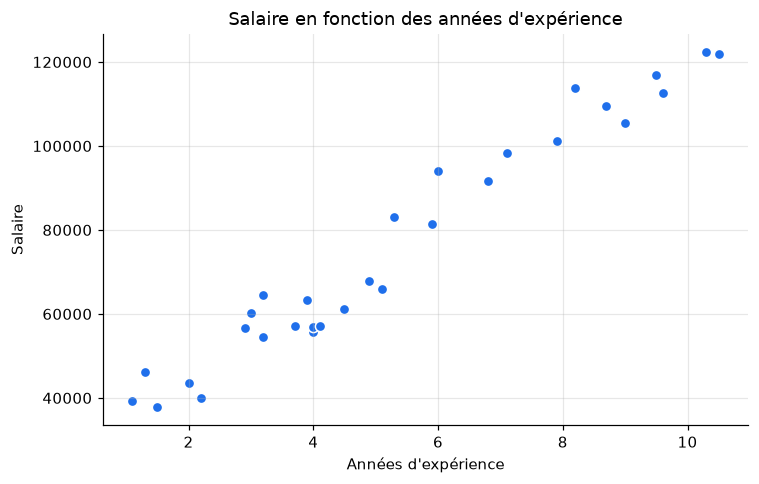

Corrélation de Pearson r = 0.9782


In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
salary.plot.scatter(x="YearsExperience", y="Salary", ax=ax, color="#1f6feb", s=45, edgecolor="white")
ax.set_title("Salaire en fonction des années d'expérience")
ax.set_xlabel("Années d'expérience"); ax.set_ylabel("Salaire")
save(fig, "p1_scatter_salary")
r_sal = salary["YearsExperience"].corr(salary["Salary"])
RESULTS["salary_pearson_r"] = float(r_sal)
print(f"Corrélation de Pearson r = {r_sal:.4f}")
# @scatter_salary

### Conclusion — nuage de points Expérience / Salaire
Les points sont **alignés autour d'une droite croissante** : le salaire augmente à peu près proportionnellement à l'expérience. Le coefficient de corrélation de Pearson **r = 0,978** confirme une relation linéaire très forte et positive (R² théorique de la régression simple sur toutes les données ≈ 0,957). Il n'y a ni courbure marquée ni point aberrant : **un modèle de régression linéaire simple est parfaitement adapté** à ce jeu de données. (Attention : la corrélation n'implique pas la causalité ; l'expérience résume aussi d'autres facteurs comme la séniorité ou le poste.)

## 4. Nuages de points du jeu Assurance (`scatter_matrix`)

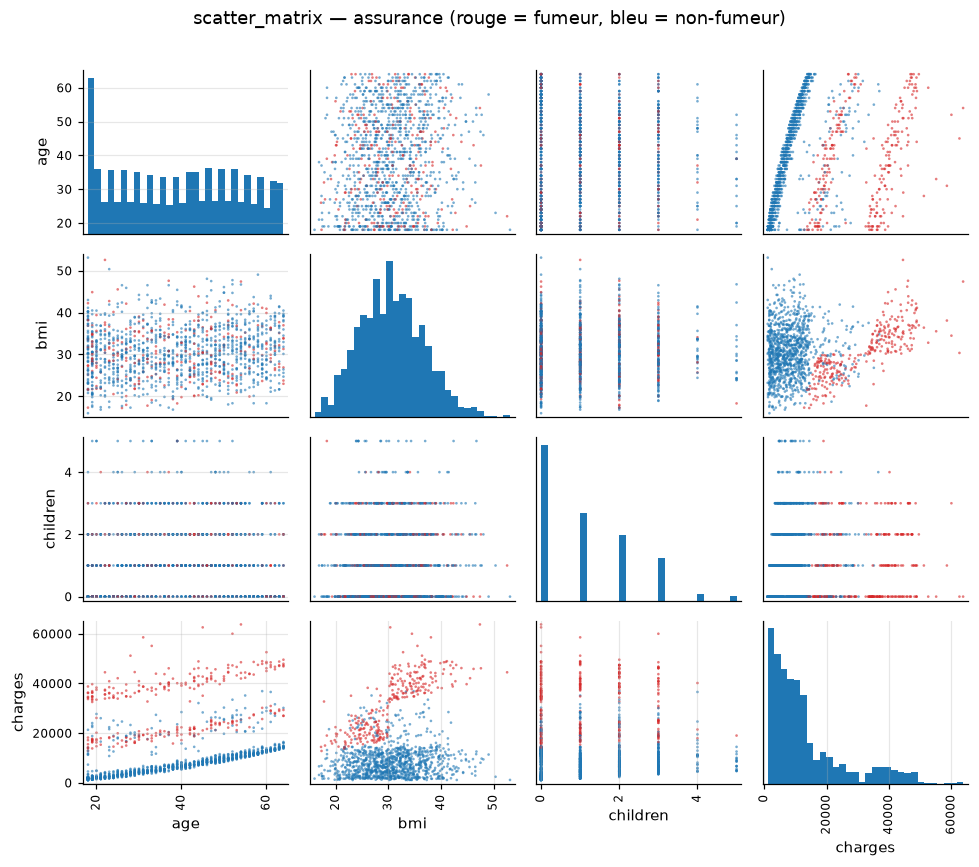

In [7]:
num_cols = ["age", "bmi", "children", "charges"]
colors = insurance["smoker"].map({"yes": "#d62728", "no": "#1f77b4"})
axes = scatter_matrix(insurance[num_cols], figsize=(9, 8), diagonal="hist", alpha=.6, s=12, c=colors, hist_kwds={"bins": 30})
plt.suptitle("scatter_matrix — assurance (rouge = fumeur, bleu = non-fumeur)")
save(plt.gcf(), "p1_scatter_matrix_insurance")
# @matrix

### Interprétation — scatter_matrix du jeu Assurance
- **charges vs age** : on observe trois « bandes » croissantes. L'âge augmente le coût de façon quasi linéaire, mais le niveau de base dépend d'un autre facteur : les **fumeurs (rouge) se situent nettement au-dessus** des non-fumeurs (bleu).
- **charges vs bmi** : pas de tendance claire globalement, mais les **fumeurs avec un IMC > 30 forment un groupe isolé à 35 000–50 000** : il existe une **interaction** fumeur × IMC.
- **charges vs children** : aucune relation visible.
- **age vs bmi** : nuage diffus, les variables explicatives sont peu corrélées entre elles (pas de problème de multicolinéarité).
- Diagonale : `age` ≈ uniforme, `bmi` ≈ cloche, `children` et `charges` asymétriques à droite.

---
# Partie 2 — Régression linéaire simple (Expérience → Salaire)

In [8]:
X = salary[["YearsExperience"]]
y = salary["Salary"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("Train :", X_train.shape, " Test :", X_test.shape)

# 1. Entraînement
lin = LinearRegression().fit(X_train, y_train)
print(f"Salaire = {lin.intercept_:.2f} + {lin.coef_[0]:.2f} x Expérience")

# 2. Prédiction sur le jeu de test
y_pred = lin.predict(X_test)
display(pd.DataFrame({"Expérience": X_test["YearsExperience"].values, "Salaire réel": y_test.values,
                      "Salaire prédit": y_pred.round(2), "Erreur": (y_test.values - y_pred).round(2)}))

Train : (24, 1)  Test : (6, 1)
Salaire = 25321.58 + 9423.82 x Expérience


,Expérience,Salaire réel,Salaire prédit,Erreur
0,9.6,112635.0,115790.21,-3155.21
1,4.9,67938.0,71498.28,-3560.28
2,8.2,113812.0,102596.87,11215.13
3,5.3,83088.0,75267.80,7820.20
4,3.2,64445.0,55477.79,8967.21
5,3.7,57189.0,60189.70,-3000.70


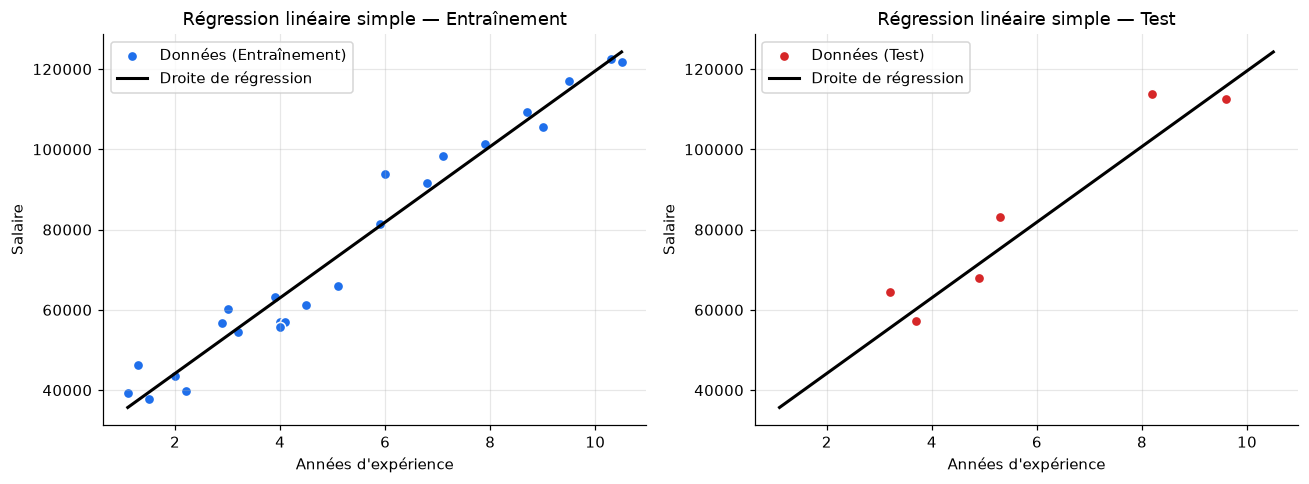

In [9]:
# 3. Visualisation
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
grid = pd.DataFrame({"YearsExperience": np.linspace(X["YearsExperience"].min(), X["YearsExperience"].max(), 100)})
for ax, (Xs, ys, lab, col) in zip(axes, [(X_train, y_train, "Entraînement", "#1f6feb"), (X_test, y_test, "Test", "#d62728")]):
    ax.scatter(Xs, ys, color=col, s=45, edgecolor="white", label=f"Données ({lab})")
    ax.plot(grid, lin.predict(grid), color="black", lw=2, label="Droite de régression")
    ax.set_title(f"Régression linéaire simple — {lab}"); ax.set_xlabel("Années d'expérience"); ax.set_ylabel("Salaire"); ax.legend()
save(fig, "p2_regression_salary")

In [10]:
# 4. Évaluation
m_train = evaluate(y_train, lin.predict(X_train))
m_test = evaluate(y_test, y_pred)
RESULTS["salary"] = {"intercept": float(lin.intercept_), "coef": float(lin.coef_[0]),
                     "n_train": len(X_train), "n_test": len(X_test), "train": m_train, "test": m_test,
                     "mean_salary": float(y.mean()), "std_salary": float(y.std())}
display(pd.DataFrame({"Train": m_train, "Test": m_test}).round(4))
print(f"RMSE test / salaire moyen = {m_test['RMSE'] / y.mean():.1%}")

,Train,Test
MSE,2.710225e+07,4.983010e+07
RMSE,5.205982e+03,7.059044e+03
MAE,4.221047e+03,6.286454e+03
R2,9.645000e-01,9.024000e-01


RMSE test / salaire moyen = 9.3%


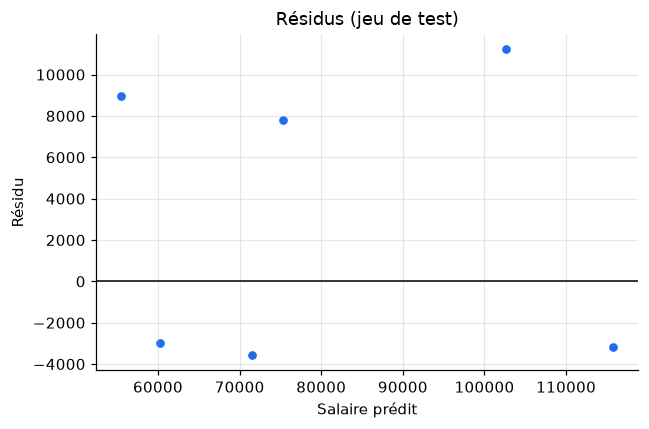

In [11]:
res = y_test - y_pred
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(y_pred, res, color="#1f6feb", s=45, edgecolor="white"); ax.axhline(0, color="k", lw=1)
ax.set_title("Résidus (jeu de test)"); ax.set_xlabel("Salaire prédit"); ax.set_ylabel("Résidu")
save(fig, "p2_residuals_salary")
# @eval_salary

### Interprétation de l'évaluation — régression simple
**Modèle appris** : `Salaire = 25 321,58 + 9 423,82 × Expérience`. Chaque année d'expérience supplémentaire augmente le salaire prédit d'environ **9 424** ; un débutant (0 an) démarre à ≈ 25 322.

| Métrique | Entraînement (24 pts) | Test (6 pts) |
|---|---|---|
| MSE | 27 102 250 | 49 830 097 |
| RMSE | 5 206 | 7 059 |
| MAE | 4 221 | 6 286 |
| R² | 0,965 | 0,902 |

- Le **RMSE test de 7 059** correspond à ≈ **9,3 %** du salaire moyen (76 003) : en moyenne, la prédiction se trompe d'environ 7 000 (MAE : 6 286 en moyenne absolue). Le RMSE est plus grand que la MAE car il pénalise davantage les grosses erreurs (ici l'observation à 8,2 ans, sous-estimée de 11 215).
- **R² = 0,90 en test** : le modèle explique 90 % de la variance des salaires non vus pendant l'entraînement.
- L'erreur de test est supérieure à celle d'entraînement, ce qui est normal ; l'écart doit toutefois être relativisé car **le jeu de test ne contient que 6 points** : les métriques sont donc très sensibles au tirage (une validation croisée donnerait une estimation plus stable).
- Avec seulement 6 résidus, aucune structure évidente n'apparaît ; l'hypothèse de linéarité, déjà soutenue par r = 0,978, reste raisonnable. **Conclusion : bon modèle, simple et interprétable.**

---
# Partie 3 — Régression linéaire multiple (Assurance)
## 1. Analyse exploratoire (EDA)

Après suppression des doublons : (1337, 7)


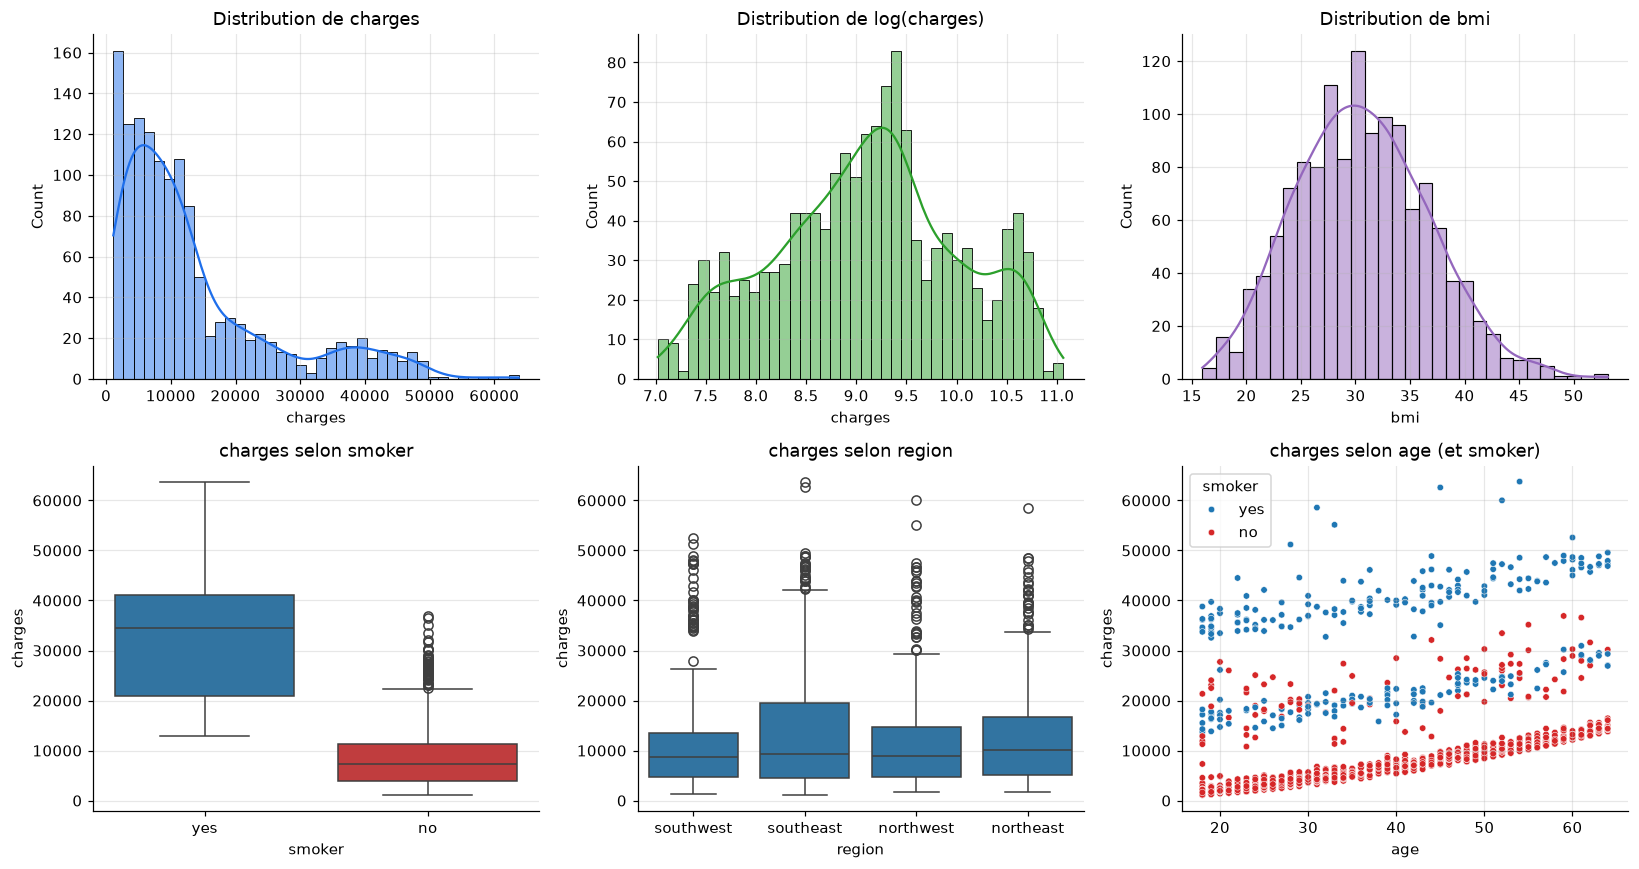

In [12]:
ins = insurance.drop_duplicates().reset_index(drop=True)
print("Après suppression des doublons :", ins.shape)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sns.histplot(ins["charges"], bins=40, kde=True, ax=axes[0, 0], color="#1f6feb"); axes[0, 0].set_title("Distribution de charges")
sns.histplot(np.log(ins["charges"]), bins=40, kde=True, ax=axes[0, 1], color="#2ca02c"); axes[0, 1].set_title("Distribution de log(charges)")
sns.histplot(ins["bmi"], bins=30, kde=True, ax=axes[0, 2], color="#9467bd"); axes[0, 2].set_title("Distribution de bmi")
sns.boxplot(data=ins, x="smoker", y="charges", ax=axes[1, 0], palette=["#1f77b4", "#d62728"]); axes[1, 0].set_title("charges selon smoker")
sns.boxplot(data=ins, x="region", y="charges", ax=axes[1, 1]); axes[1, 1].set_title("charges selon region")
sns.scatterplot(data=ins, x="age", y="charges", hue="smoker", ax=axes[1, 2], s=18, palette=["#1f77b4", "#d62728"]); axes[1, 2].set_title("charges selon age (et smoker)")
save(fig, "p3_eda")

        count     mean   median
smoker                         
no       1063   8440.7   7345.7
yes       274  32050.2  34456.3
        count     mean  median
sex                           
female    662  12569.6  9413.0
male      675  13975.0  9377.9
           count     mean   median
region                            
northeast    324  13406.4  10057.7
northwest    324  12450.8   8977.0
southeast    364  14735.4   9294.1
southwest    325  12346.9   8798.6
          count     mean
children                
0           573  12384.7
1           324  12731.2
2           240  15073.6
3           157  15355.3
4            25  13850.7
5            18   8786.0
Valeurs aberrantes (IQR) sur bmi : 9


,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,0,0,1
1,18,1,33.770,1,0,1725.55230,0,1,0
2,28,1,33.000,3,0,4449.46200,0,1,0
3,33,1,22.705,0,0,21984.47061,1,0,0
4,32,1,28.880,0,0,3866.85520,1,0,0


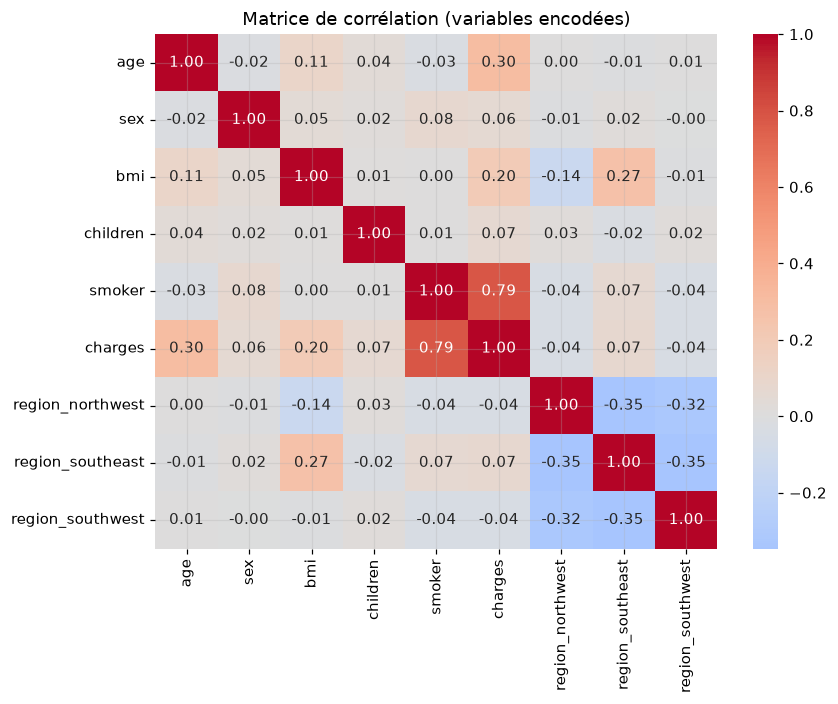

In [13]:
print(ins.groupby("smoker")["charges"].agg(["count", "mean", "median"]).round(1))
print(ins.groupby("sex")["charges"].agg(["count", "mean", "median"]).round(1))
print(ins.groupby("region")["charges"].agg(["count", "mean", "median"]).round(1))
print(ins.groupby("children")["charges"].agg(["count", "mean"]).round(1))
print("Valeurs aberrantes (IQR) sur bmi :", int(((ins.bmi < ins.bmi.quantile(.25) - 1.5 * (ins.bmi.quantile(.75) - ins.bmi.quantile(.25))) |
                                              (ins.bmi > ins.bmi.quantile(.75) + 1.5 * (ins.bmi.quantile(.75) - ins.bmi.quantile(.25)))).sum()))

# Encodage des variables catégorielles
enc = ins.copy()
enc["sex"] = (enc["sex"] == "male").astype(int)
enc["smoker"] = (enc["smoker"] == "yes").astype(int)
enc = pd.get_dummies(enc, columns=["region"], drop_first=True, dtype=int)
display(enc.head())

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(enc.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Matrice de corrélation (variables encodées)")
save(fig, "p3_corr_heatmap")
# @eda

### Conclusions de l'EDA — Assurance
1. **Qualité des données** : pas de valeur manquante, 1 doublon supprimé (1 337 lignes conservées), variables catégorielles propres (encodées en 0/1 et one-hot avec `drop_first` pour la région).
2. **Cible `charges`** : très asymétrique à droite (skewness 1,52). Le passage au logarithme rend la distribution beaucoup plus symétrique ; on garde néanmoins la cible brute pour que les métriques restent exprimées en dollars.
3. **`smoker` est le facteur dominant** : les fumeurs coûtent en moyenne **32 050 contre 8 441** pour les non-fumeurs (×3,8) ; corrélation avec `charges` : **0,79**.
4. **`age`** : relation croissante nette (corrélation 0,30). **`bmi`** : effet visible surtout chez les fumeurs (corrélation globale 0,20).
5. **Variables peu informatives** : `sex` (moyennes 12 570 F / 13 975 H, médianes quasi identiques), `region` (moyennes entre 12 347 et 14 735) et `children` (corrélation 0,07) ont un effet très faible.
6. **Pas de multicolinéarité** : les variables explicatives sont faiblement corrélées entre elles (voir la matrice).
7. **Limite de la linéarité** : le nuage `charges` vs `age` forme plusieurs groupes et l'effet du `bmi` dépend du statut fumeur → un modèle purement additif ne capturera pas tout.

## 2. Sélection des 3 propriétés les plus importantes
Quatre techniques complémentaires sont appliquées, puis leurs rangs sont agrégés :
corrélation de Pearson, test F (`f_regression`), information mutuelle et importance par forêt aléatoire.

,|corr| (Pearson),Score F,Info. mutuelle,Importance RF,Rang moyen
smoker,0.7872,2175.7369,0.3693,0.6194,1.25
age,0.2983,130.4030,1.4979,0.1290,2.00
bmi,0.1984,54.7027,0.0739,0.2115,3.25
children,0.0674,6.0903,0.1608,0.0190,4.50
sex,0.0580,4.5130,0.1763,0.0058,5.25
region_southeast,0.0736,7.2666,0.0350,0.0053,5.50
region_northwest,0.0387,2.0019,0.0568,0.0060,6.75
region_southwest,0.0436,2.5470,0.0025,0.0041,7.50


Les 3 propriétés retenues : ['smoker', 'age', 'bmi']


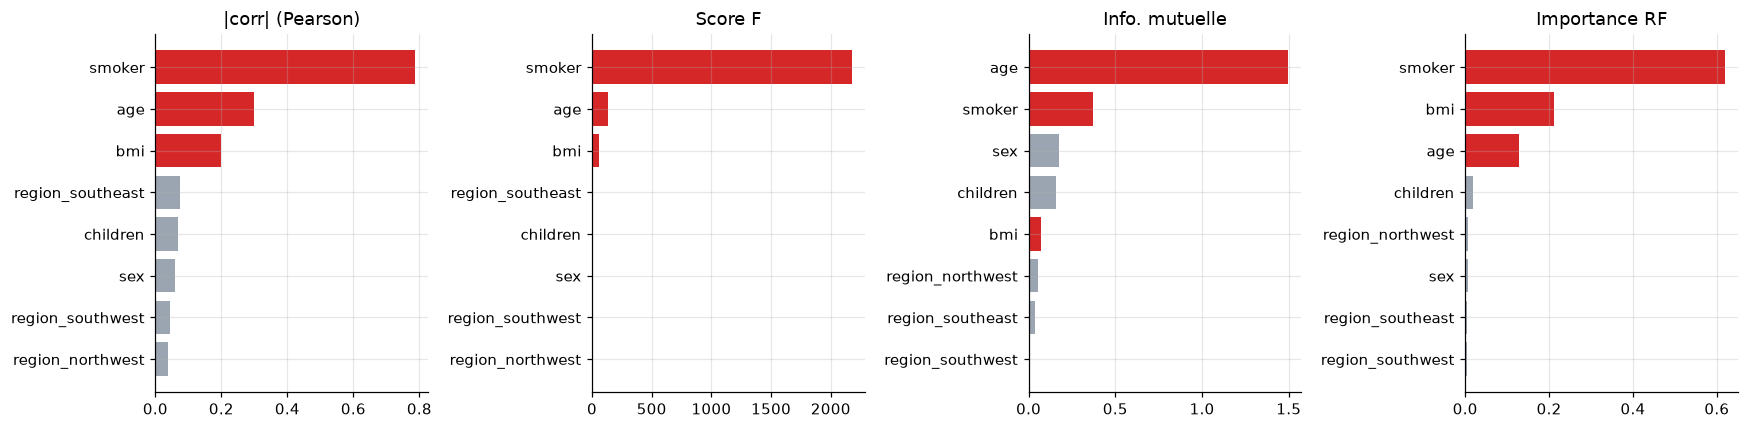

In [14]:
features = [c for c in enc.columns if c != "charges"]
Xa, ya = enc[features], enc["charges"]

corr = Xa.corrwith(ya).abs()
f_scores, _ = f_regression(Xa, ya)
mi = mutual_info_regression(Xa, ya, random_state=SEED)
rf = RandomForestRegressor(n_estimators=300, random_state=SEED).fit(Xa, ya)

sel = pd.DataFrame({"|corr| (Pearson)": corr, "Score F": f_scores, "Info. mutuelle": mi, "Importance RF": rf.feature_importances_}, index=features)
ranks = sel.rank(ascending=False)
sel["Rang moyen"] = ranks.mean(axis=1)
sel = sel.sort_values("Rang moyen")
display(sel.round(4))
top3 = list(sel.index[:3])
print("Les 3 propriétés retenues :", top3)
RESULTS["selection"] = {"table": sel.round(5).reset_index().rename(columns={"index": "feature"}).to_dict("records"), "top3": top3}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["|corr| (Pearson)", "Score F", "Info. mutuelle", "Importance RF"]):
    s = sel[col].sort_values()
    ax.barh(s.index, s.values, color=["#d62728" if i in top3 else "#9aa5b1" for i in s.index]); ax.set_title(col)
save(fig, "p3_feature_selection")
# @selection

### Justification du choix des 3 propriétés
Les quatre méthodes ont été combinées (moyenne des rangs) pour ne pas dépendre d'un seul critère :

| Propriété | Rang moyen |
|---|---|
| **smoker** | **1,25** |
| **age** | **2,00** |
| **bmi** | **3,25** |
| children | 4,50 |
| sex | 5,25 |
| region_southeast | 5,50 |

- **smoker** est 1er ou 2e partout : corrélation 0,79, score F = 2 176, importance de la forêt aléatoire = 62 %.
- **age** : 2e pour la corrélation et le score F, 1er pour l'information mutuelle (1,50) ; importance RF 13 %.
- **bmi** : 3e pour la corrélation et le score F, et 2e pour l'importance RF (21 %, devant `age`), car la forêt aléatoire capte l'interaction avec le tabagisme que les mesures linéaires sous-estiment (son information mutuelle est faible, 0,07).
- Les autres variables ont une importance RF < 2 % et des scores F faibles : elles sont écartées.
- **Vérification a posteriori** (partie 3, §7) : le modèle à 3 variables atteint pratiquement la même performance (RMSE test 5 987) que celui utilisant les 8 variables (5 956). Le choix est donc justifié : un modèle plus simple sans perte notable.

## 3. Standardisation des propriétés retenues
On utilise `StandardScaler` (z = (x − μ) / σ). Le scaler est **ajusté sur le jeu d'entraînement uniquement**
afin d'éviter toute fuite de données (data leakage) vers le jeu de test.

In [15]:
print(enc[top3].describe().loc[["mean", "std", "min", "max"]].round(2))
X3, y3 = enc[top3], enc["charges"]
X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, test_size=0.2, random_state=SEED)
scaler = StandardScaler().fit(X3_train)
X3_train_s = pd.DataFrame(scaler.transform(X3_train), columns=top3, index=X3_train.index)
X3_test_s = pd.DataFrame(scaler.transform(X3_test), columns=top3, index=X3_test.index)
print("\nAprès standardisation (train) :")
print(X3_train_s.describe().loc[["mean", "std"]].round(3))
# @scaling

      smoker    age    bmi
mean     0.2  39.22  30.66
std      0.4  14.04   6.10
min      0.0  18.00  15.96
max      1.0  64.00  53.13

Après standardisation (train) :
      smoker  age  bmi
mean     0.0  0.0  0.0
std      1.0  1.0  1.0


### Justification du choix : standardisation (`StandardScaler`)
- Les propriétés ont des échelles très différentes (`smoker` ∈ {0,1}, `age` ∈ [18 ; 64], `bmi` ∈ [16 ; 53]). La régression linéaire par moindres carrés n'en a pas besoin pour *prédire* (ses prédictions sont invariantes à l'échelle), mais la mise à l'échelle rend les **coefficients comparables** entre variables et conditionne mieux le problème numérique.
- **Standardisation plutôt que normalisation min-max** : `bmi` est quasi gaussienne et contient des valeurs extrêmes (9 aberrations) ; le min-max, qui dépend du minimum et du maximum, serait fortement influencé par ces points, alors que la standardisation (moyenne 0, écart-type 1) y est moins sensible et reste la convention pour les modèles linéaires.
- Le scaler est **ajusté uniquement sur le jeu d'entraînement** (moyenne et écart-type de l'entraînement appliqués au test) pour éviter toute fuite d'information ; on vérifie bien moyenne = 0 et écart-type = 1 après transformation.

## 4–5. Entraînement et prédiction

In [16]:
mlr = LinearRegression().fit(X3_train_s, y3_train)
coefs = pd.Series(mlr.coef_, index=top3)
print(f"charges = {mlr.intercept_:.2f} + " + " + ".join(f"({v:.2f} x {k}_std)" for k, v in coefs.items()))
y3_pred = mlr.predict(X3_test_s)
display(pd.DataFrame({"charges réelles": y3_test.values, "charges prédites": y3_pred.round(2)}, index=y3_test.index).head(10))

charges = 13030.20 + (9232.94 x smoker_std) + (3524.26 x age_std) + (1843.75 x bmi_std)


,charges réelles,charges prédites
899,8688.85885,8433.67
1063,5708.86700,4336.47
1255,11436.73815,13165.04
298,38746.35510,30593.70
237,4463.20510,8738.64
481,9304.70190,13004.19
240,38511.62830,29273.64
277,2150.46900,2177.09
415,7345.72660,10922.95
706,10264.44210,10315.83


## 6. Visualisation

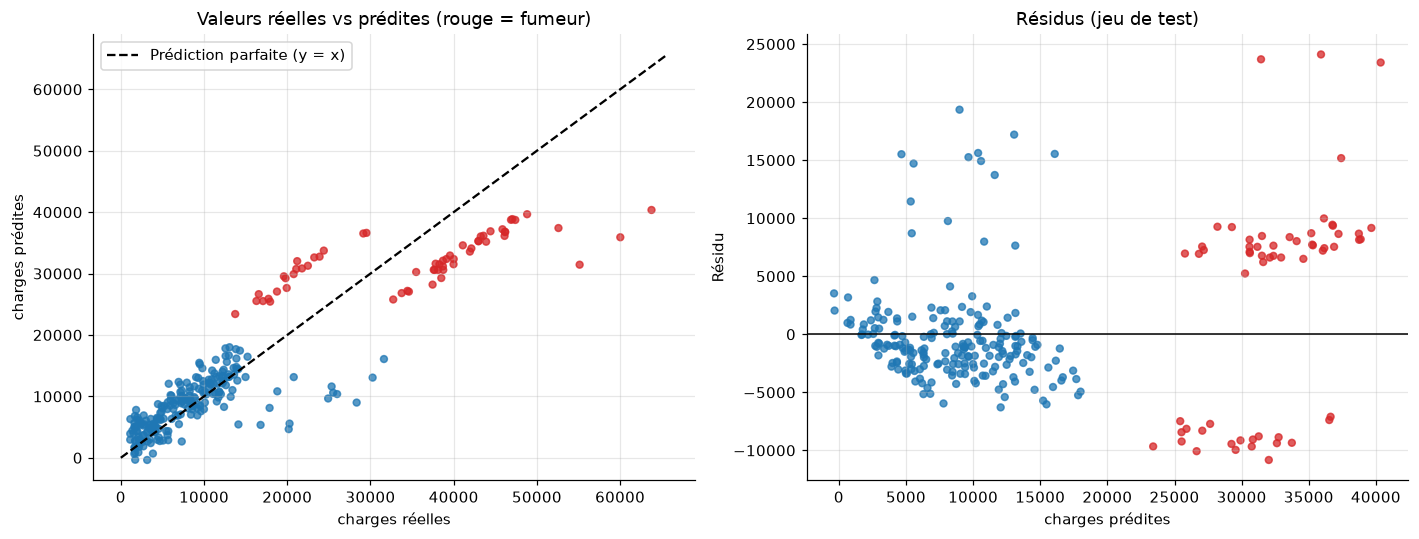

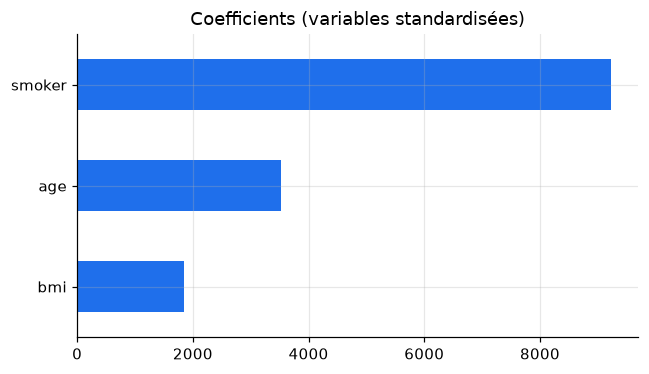

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sm = X3_test["smoker"].map({1: "#d62728", 0: "#1f77b4"})
axes[0].scatter(y3_test, y3_pred, c=sm, s=20, alpha=.75)
lim = [0, max(y3_test.max(), y3_pred.max()) * 1.03]
axes[0].plot(lim, lim, "k--", lw=1.5, label="Prédiction parfaite (y = x)")
axes[0].set_xlabel("charges réelles"); axes[0].set_ylabel("charges prédites"); axes[0].set_title("Valeurs réelles vs prédites (rouge = fumeur)"); axes[0].legend()
axes[1].scatter(y3_pred, y3_test - y3_pred, c=sm, s=20, alpha=.75); axes[1].axhline(0, color="k", lw=1)
axes[1].set_xlabel("charges prédites"); axes[1].set_ylabel("Résidu"); axes[1].set_title("Résidus (jeu de test)")
save(fig, "p3_regression_insurance")

fig, ax = plt.subplots(figsize=(6, 3.5))
coefs.sort_values().plot.barh(ax=ax, color="#1f6feb"); ax.set_title("Coefficients (variables standardisées)")
save(fig, "p3_coefficients")
# @viz_ins

### Lecture du graphique
- Les points suivent la diagonale (prédiction parfaite) mais **s'en écartent nettement en deux endroits** : les non-fumeurs réellement très coûteux (bleu, sous la diagonale) sont **sous-estimés**, et les fumeurs forment deux groupes dont l'un est **surestimé** et l'autre **sous-estimé**.
- Les résidus ne sont pas répartis aléatoirement : les fumeurs forment deux paquets (≈ +8 000 et ≈ −9 000) et la variance augmente avec la valeur prédite (hétéroscédasticité). La cause est l'interaction fumeur × IMC mise en évidence par l'EDA, qu'un modèle linéaire additif ne peut pas représenter.
- **Coefficients standardisés** : smoker +9 233, age +3 524, bmi +1 844 (par écart-type). En unités d'origine : être fumeur ajoute ≈ **23 000** de charges, chaque année d'âge ≈ **251**, chaque point d'IMC ≈ **302**, toutes choses égales par ailleurs. L'ordonnée à l'origine (13 030) correspond aux charges moyennes d'entraînement (variables centrées).

## 7. Évaluation

In [18]:
m3_train = evaluate(y3_train, mlr.predict(X3_train_s))
m3_test = evaluate(y3_test, y3_pred)
# Référence : modèle avec toutes les variables
sc_all = StandardScaler().fit(Xa.loc[X3_train.index])
mlr_all = LinearRegression().fit(sc_all.transform(Xa.loc[X3_train.index]), y3_train)
m3_all = evaluate(y3_test, mlr_all.predict(sc_all.transform(Xa.loc[X3_test.index])))
# Référence : prédire toujours la moyenne
m3_base = evaluate(y3_test, np.full(len(y3_test), y3_train.mean()))
RESULTS["insurance"] = {"intercept": float(mlr.intercept_), "coefs": coefs.round(2).to_dict(), "n_train": len(X3_train), "n_test": len(X3_test),
                        "train": m3_train, "test": m3_test, "all_features_test": m3_all, "baseline_test": m3_base,
                        "mean_charges": float(ins.charges.mean()), "std_charges": float(ins.charges.std())}
display(pd.DataFrame({"Train": m3_train, "Test": m3_test, "Toutes variables (test)": m3_all, "Référence : moyenne (test)": m3_base}).round(4))
# @eval_ins

,Train,Test,Toutes variables (test),Référence : moyenne (test)
MSE,3.748549e+07,3.584157e+07,3.547802e+07,1.852981e+08
RMSE,6.122539e+03,5.986783e+03,5.956343e+03,1.361243e+04
MAE,4.227827e+03,4.191704e+03,4.177046e+03,9.861798e+03
R2,7.262000e-01,8.050000e-01,8.069000e-01,-8.400000e-03


### Interprétation de l'évaluation — régression multiple

| Métrique | Entraînement (1 069) | Test (268) | 8 variables (test) | Référence : moyenne (test) |
|---|---|---|---|---|
| MSE | 37 485 489 | 35 841 575 | 35 478 021 | 185 298 142 |
| RMSE | 6 123 | 5 987 | 5 956 | 13 612 |
| MAE | 4 228 | 4 192 | 4 177 | 9 862 |
| R² | 0,726 | 0,805 | 0,807 | −0,008 |

- Le modèle explique **≈ 80 % de la variance** des charges sur le jeu de test et **divise l'erreur par 2,3** par rapport à une prédiction naïve par la moyenne (RMSE 5 987 contre 13 612).
- Erreur typique : **MAE ≈ 4 192**, soit ≈ 32 % des charges moyennes (13 270). Le RMSE (5 987) est nettement supérieur à la MAE à cause de quelques gros écarts sur des assurés très coûteux.
- L'écart train/test est faible et **dans le sens inverse du sur-apprentissage** (R² test 0,805 > train 0,726) : il n'y a pas de sur-apprentissage, ce résultat vient d'un jeu de test contenant moins de cas atypiques ; il serait confirmé par une validation croisée.
- Le modèle à **3 variables est quasiment aussi bon que celui à 8** (RMSE 5 987 vs 5 956 ; MAE 4 192 vs 4 177) : les 5 variables écartées n'apportent presque rien, ce qui valide la sélection.
- **Limites et pistes d'amélioration** : la structure des résidus montre une non-linéarité. Il est probable qu'une variable d'interaction `smoker × bmi`, un terme quadratique en `age`, ou une cible transformée par le logarithme, améliorerait sensiblement le modèle (pistes non testées dans cet atelier).

---
# Partie 4 — Régression linéaire vs polynomiale (China GDP)

,Year,Value
0,1960,5.918412e+10
1,1961,4.955705e+10
2,1962,4.668518e+10
3,1963,5.009730e+10
4,1964,5.906225e+10


,count,mean,std,min,25%,50%,75%,max
Year,55.0,1.987000e+03,1.602082e+01,1.960000e+03,1.973500e+03,1.987000e+03,2.000500e+03,2.014000e+03
Value,55.0,1.437042e+12,2.500085e+12,4.668518e+10,1.395123e+11,3.074796e+11,1.268748e+12,1.035483e+13


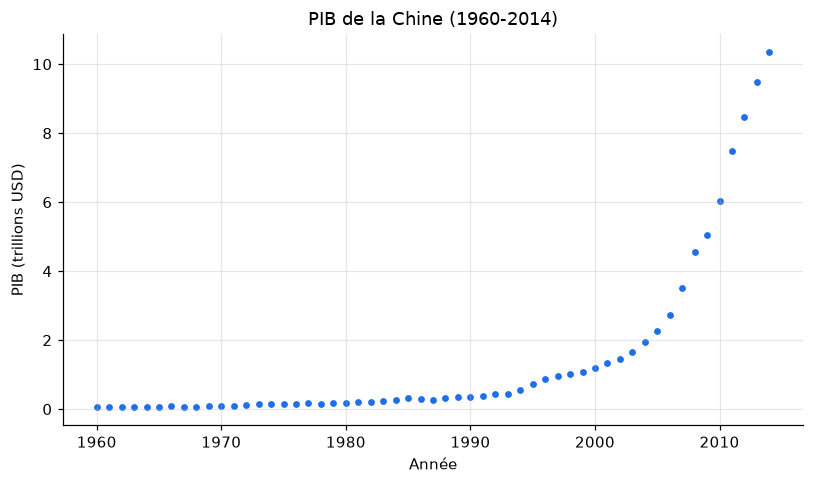

In [19]:
display(gdp.head()); display(gdp.describe().T)
gdp["GDP_Tn"] = gdp["Value"] / 1e12            # PIB en milliers de milliards (trillions) de dollars
gdp["t"] = gdp["Year"] - gdp["Year"].min()     # années écoulées depuis 1960 (meilleur conditionnement numérique)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(gdp["Year"], gdp["GDP_Tn"], color="#1f6feb", s=30, edgecolor="white")
ax.set_title("PIB de la Chine (1960-2014)"); ax.set_xlabel("Année"); ax.set_ylabel("PIB (trillions USD)")
save(fig, "p4_gdp_raw")

,RMSE CV (moy.),RMSE CV (écart-type)
degré,,
1,1.7493,0.5253
2,1.0796,0.3127
3,0.5376,0.1012
4,0.2512,0.0653
5,0.2157,0.1004
6,0.2322,0.0952
7,0.1998,0.0508


Minimum de la RMSE CV au degré 7 ; seuil 1-SE = 0.2506 ; degré retenu : 5


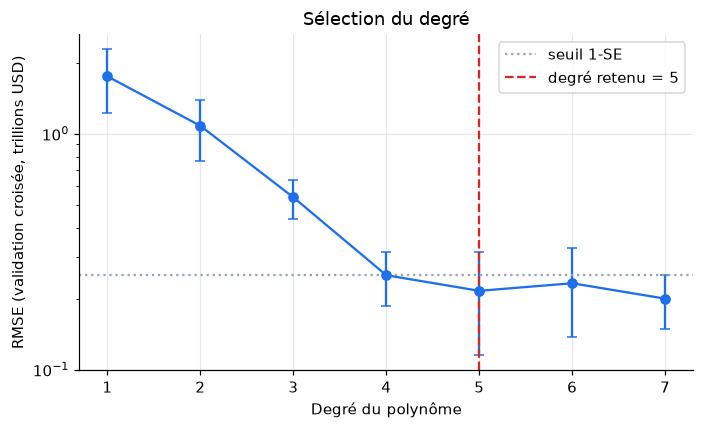

In [20]:
Xg, yg = gdp[["t"]], gdp["GDP_Tn"]
Xg_train, Xg_test, yg_train, yg_test = train_test_split(Xg, yg, test_size=0.2, random_state=SEED)

# Choix du degré par validation croisée (5 plis) sur le jeu d'entraînement uniquement
kf = KFold(5, shuffle=True, random_state=SEED)
rows = []
for d in range(1, 8):
    pipe = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())
    cv = -cross_val_score(pipe, Xg_train, yg_train, cv=kf, scoring="neg_root_mean_squared_error")
    rows.append({"degré": d, "RMSE CV (moy.)": cv.mean(), "RMSE CV (écart-type)": cv.std()})
cvdf = pd.DataFrame(rows).set_index("degré")
display(cvdf.round(4))
# Règle de l'écart-type (1-SE) : on retient le plus petit degré dont l'erreur reste dans 1 écart-type du minimum
# (modèle le plus simple statistiquement équivalent au meilleur -> limite le sur-apprentissage).
imin = cvdf["RMSE CV (moy.)"].idxmin()
seuil = cvdf.loc[imin, "RMSE CV (moy.)"] + cvdf.loc[imin, "RMSE CV (écart-type)"]
best_deg = int(cvdf[cvdf["RMSE CV (moy.)"] <= seuil].index.min())
print(f"Minimum de la RMSE CV au degré {imin} ; seuil 1-SE = {seuil:.4f} ; degré retenu : {best_deg}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.errorbar(cvdf.index, cvdf["RMSE CV (moy.)"], yerr=cvdf["RMSE CV (écart-type)"], marker="o", color="#1f6feb", capsize=3)
ax.axhline(seuil, color="#9aa5b1", ls=":", label="seuil 1-SE"); ax.axvline(best_deg, color="#d62728", ls="--", label=f"degré retenu = {best_deg}"); ax.set_yscale("log")
ax.set_xlabel("Degré du polynôme"); ax.set_ylabel("RMSE (validation croisée, trillions USD)"); ax.set_title("Sélection du degré"); ax.legend()
save(fig, "p4_degree_selection")
# @degree

### Choix du degré du polynôme
L'erreur de validation croisée chute fortement de 1,75 (degré 1) à 0,25 (degré 4) puis se stabilise : au-delà du degré 4–5, le gain n'est plus significatif devant l'écart-type entre plis. Le minimum « brut » est au degré 7 (0,1998), mais en appliquant la **règle de l'écart-type (1-SE)** on retient le **plus petit degré dont l'erreur est dans un écart-type du minimum, soit le degré 5** : modèle plus simple, statistiquement équivalent, moins exposé au sur-apprentissage (un degré 7 produisait d'ailleurs des extrapolations absurdes, PIB négatif).

## 1–2. Entraînement et prédiction des deux modèles

In [21]:
lin_g = LinearRegression().fit(Xg_train, yg_train)
poly_g = make_pipeline(PolynomialFeatures(best_deg, include_bias=False), StandardScaler(), LinearRegression()).fit(Xg_train, yg_train)
pred_lin, pred_poly = lin_g.predict(Xg_test), poly_g.predict(Xg_test)
display(pd.DataFrame({"Année": gdp.loc[Xg_test.index, "Year"].values, "PIB réel": yg_test.values.round(3),
                      "Prédit (linéaire)": pred_lin.round(3), f"Prédit (poly. deg {best_deg})": pred_poly.round(3)}).sort_values("Année"))

,Année,PIB réel,Prédit (linéaire),Prédit (poly. deg 5)
1,1965,0.070,-0.964,0.088
9,1972,0.112,-0.196,0.077
3,1973,0.137,-0.087,0.084
4,1979,0.177,0.572,0.181
7,1986,0.299,1.340,0.332
0,1991,0.381,1.889,0.438
2,1992,0.425,1.998,0.467
6,2001,1.332,2.986,1.346
8,2003,1.650,3.205,1.872
5,2009,5.059,3.864,5.058


## 3. Visualisation des deux modèles

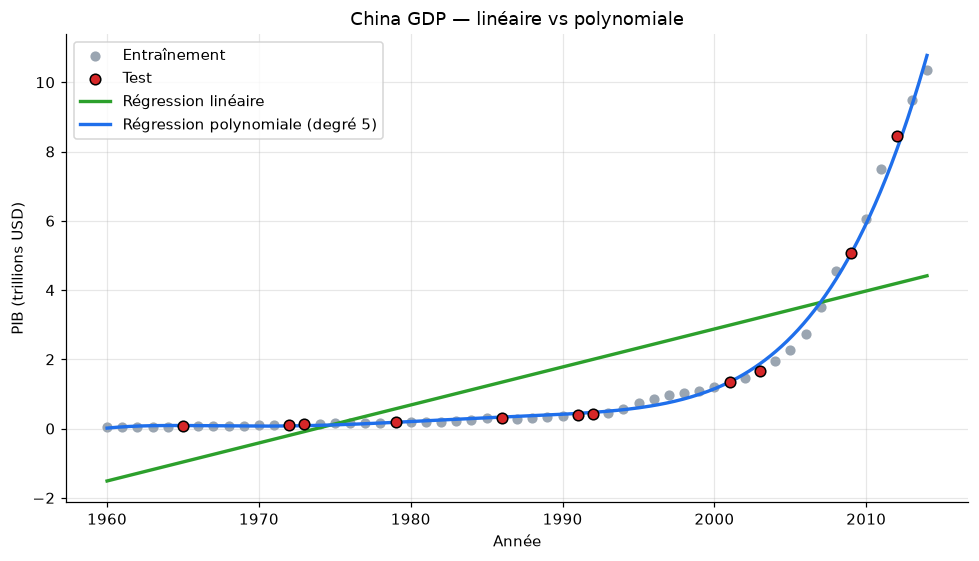

In [22]:
tt = pd.DataFrame({"t": np.linspace(0, 54, 300)})
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.scatter(gdp.loc[Xg_train.index, "Year"], yg_train, color="#9aa5b1", s=32, label="Entraînement")
ax.scatter(gdp.loc[Xg_test.index, "Year"], yg_test, color="#d62728", s=48, edgecolor="k", zorder=3, label="Test")
ax.plot(tt["t"] + 1960, lin_g.predict(tt), color="#2ca02c", lw=2.2, label="Régression linéaire")
ax.plot(tt["t"] + 1960, poly_g.predict(tt), color="#1f6feb", lw=2.2, label=f"Régression polynomiale (degré {best_deg})")
ax.set_xlabel("Année"); ax.set_ylabel("PIB (trillions USD)"); ax.set_title("China GDP — linéaire vs polynomiale"); ax.legend()
save(fig, "p4_regression_gdp")
# @viz_gdp

### Lecture du graphique
- Le PIB de la Chine suit une courbe **quasi exponentielle** : presque plat jusqu'à la fin des années 1980, puis croissance de plus en plus rapide à partir des années 2000 (10,4 trillions USD en 2014).
- La **droite** ne peut pas épouser cette forme : elle surestime systématiquement entre 1975 et 2007 et sous-estime fortement après 2008. Elle prédit même un **PIB négatif avant 1975** (−0,96 en 1965), ce qui est absurde.
- La **courbe polynomiale de degré 5** suit fidèlement les données sur toute la période, aussi bien pour les points d'entraînement que pour ceux du jeu de test.
- Remarque : la régression polynomiale reste une régression linéaire *multiple* : le modèle est linéaire dans ses paramètres, avec les variables t, t², t³, t⁴, t⁵ construites par `PolynomialFeatures`.

## 4. Évaluation des deux modèles

,Linéaire - Train,Linéaire - Test,Polynomiale - Train,Polynomiale - Test
MSE,2.9277,2.9097,0.0264,0.0214
RMSE,1.7110,1.7058,0.1624,0.1463
MAE,1.2845,1.3414,0.1025,0.0818
R2,0.5131,0.5578,0.9956,0.9967


Extrapolation 2030 (trillions USD) : linéaire = 6.17 | polynomiale = 72.76


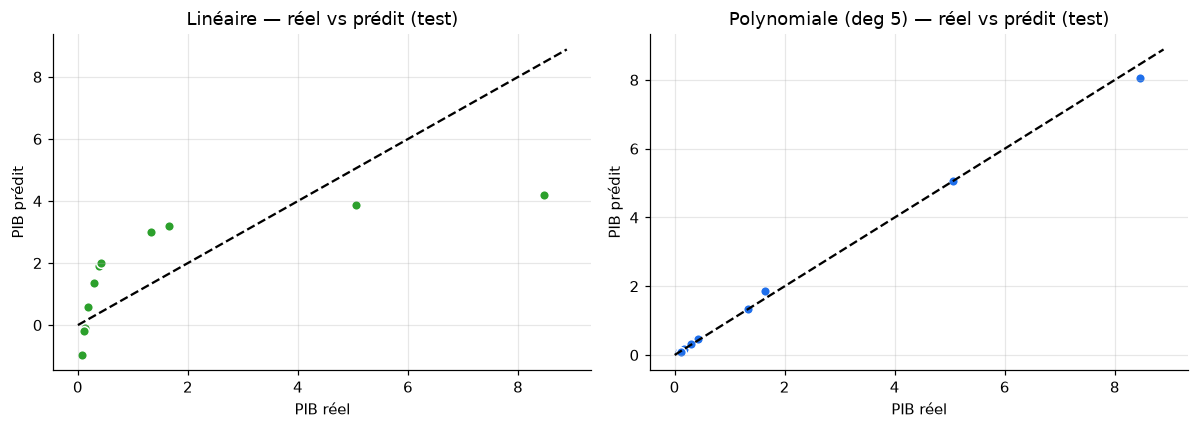

In [23]:
g = {"linear": {"train": evaluate(yg_train, lin_g.predict(Xg_train)), "test": evaluate(yg_test, pred_lin)},
     "poly": {"train": evaluate(yg_train, poly_g.predict(Xg_train)), "test": evaluate(yg_test, pred_poly)}}
g.update({"degree": best_deg, "cv_min_degree": int(imin), "n_train": len(Xg_train), "n_test": len(Xg_test), "cv": cvdf.round(5).reset_index().to_dict("records"),
          "mean_gdp": float(yg.mean()), "extrap_2030_linear": float(lin_g.predict(pd.DataFrame({"t": [70]}))[0]),
          "extrap_2030_poly": float(poly_g.predict(pd.DataFrame({"t": [70]}))[0])})
RESULTS["gdp"] = g
display(pd.DataFrame({"Linéaire - Train": g["linear"]["train"], "Linéaire - Test": g["linear"]["test"],
                      "Polynomiale - Train": g["poly"]["train"], "Polynomiale - Test": g["poly"]["test"]}).round(4))
print("Extrapolation 2030 (trillions USD) : linéaire =", round(g["extrap_2030_linear"], 2), "| polynomiale =", round(g["extrap_2030_poly"], 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (m, pr, col, t) in zip(axes, [(lin_g, pred_lin, "#2ca02c", "Linéaire"), (poly_g, pred_poly, "#1f6feb", f"Polynomiale (deg {best_deg})")]):
    ax.scatter(yg_test, pr, color=col, s=40, edgecolor="white"); lim = [0, yg_test.max() * 1.05]
    ax.plot(lim, lim, "k--"); ax.set_title(f"{t} — réel vs prédit (test)"); ax.set_xlabel("PIB réel"); ax.set_ylabel("PIB prédit")
save(fig, "p4_pred_vs_real")
# @eval_gdp

### Interprétation de l'évaluation — linéaire vs polynomiale (unités : trillions USD)

| Métrique | Linéaire (train) | Linéaire (test) | Polynomiale d°5 (train) | Polynomiale d°5 (test) |
|---|---|---|---|---|
| MSE | 2,928 | 2,910 | 0,0264 | 0,0214 |
| RMSE | 1,711 | 1,706 | 0,1624 | 0,1463 |
| MAE | 1,284 | 1,341 | 0,1025 | 0,0818 |
| R² | 0,513 | 0,558 | 0,9956 | 0,9967 |

- **Modèle linéaire : sous-apprentissage (underfitting).** Erreur élevée à la fois en entraînement et en test (RMSE ≈ 1,7 trillion pour un PIB moyen de 1,44) et R² ≈ 0,5 : le modèle est trop simple pour la forme exponentielle des données. Les erreurs train et test étant proches, ce n'est pas un problème de généralisation mais de **biais**.
- **Modèle polynomial : excellent ajustement.** Le RMSE est **≈ 11,7 fois plus faible** (0,146 contre 1,706), R² ≈ 0,997. Les erreurs de test et d'entraînement sont du même ordre (0,146 vs 0,162) : pas de sur-apprentissage visible sur ce découpage.
- **Précaution — interpolation vs extrapolation.** Un polynôme est fiable *dans* la plage 1960–2014 mais **diverge en dehors** : pour 2030, la droite prédit 6,2 et le polynôme 72,8 trillions USD, deux valeurs peu réalistes (le PIB de 2014 est de 10,4). Ces modèles servent à décrire le passé, pas à prévoir l'avenir ; un modèle exponentiel (régression sur log(PIB)) ou logistique serait plus approprié pour de la prévision.
- Le jeu de test ne comptant que 11 points, les métriques restent sensibles au tirage ; le **ordre de grandeur de l'écart** entre les deux modèles est néanmoins très net.

In [24]:
with open("results.json", "w", encoding="utf-8") as f:
    json.dump(RESULTS, f, indent=2, ensure_ascii=False)
print("results.json sauvegardé")

results.json sauvegardé
